In [4]:
import os
import sys

assert "jax" not in sys.modules, "jax already imported: you must restart your runtime"
os.environ['XLA_FLAGS'] = "--xla_force_host_platform_device_count=4"

AssertionError: jax already imported: you must restart your runtime

In [5]:
import jax
import jax.numpy as jnp
from jax.typing import ArrayLike

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

from skmisc.loess import loess

from epiweeks import Week

import arviz as az

import numpy as np
import numpyro
import numpyro.distributions as dist

from pyrenew import observation, process, randomvariable, model, latent
from pyrenew.model.severe_pri_model import (
    HospObservationProcess,
    LatentInfectionProcess,
    PolyVisitObservationProcess,
    PyrenewModel,
)
import pyrenew.transformation as transformation
import pyrenew.transformation as t
from pyrenew.latent import InfectionInitializationProcess, InitializeInfectionsZeroPad
from pyrenew.deterministic import DeterministicPMF
from pyrenew.metaclass import RandomVariable
from pyrenew.randomvariable import DistributionalVariable, TransformedVariable


In [6]:
def conv(a: ArrayLike, b: ArrayLike) -> ArrayLike:
    """
    Helper function for convolution.
    """
    m = len(a)
    n = len(b)
    c = np.zeros(m + n - 1)

    for i in range(m):
        for j in range(n):
            c[i + j] += a[i] * b[j]
    return c

def gamma_convert_param(mean, sd):
    shape = (mean**2) / (sd**2)
    scale = (sd**2) / mean
    return shape, scale

def format_quarterly_axis(ax):
    """
    Format a Matplotlib time axis to show quarterly ticks (Jan, Apr, Jul, Oct),
    with the year label shown only under January.
    """
    locator = mdates.MonthLocator(bymonth=[1, 4, 7, 10])
    ax.xaxis.set_major_locator(locator)

    def _custom_fmt(x, pos):
        date = mdates.num2date(x)
        if date.month == 1:
            return f"{date.strftime('%b')}\n{date.year}"
        return date.strftime('%b')

    ax.xaxis.set_major_formatter(FuncFormatter(_custom_fmt))
    return ax


### Data

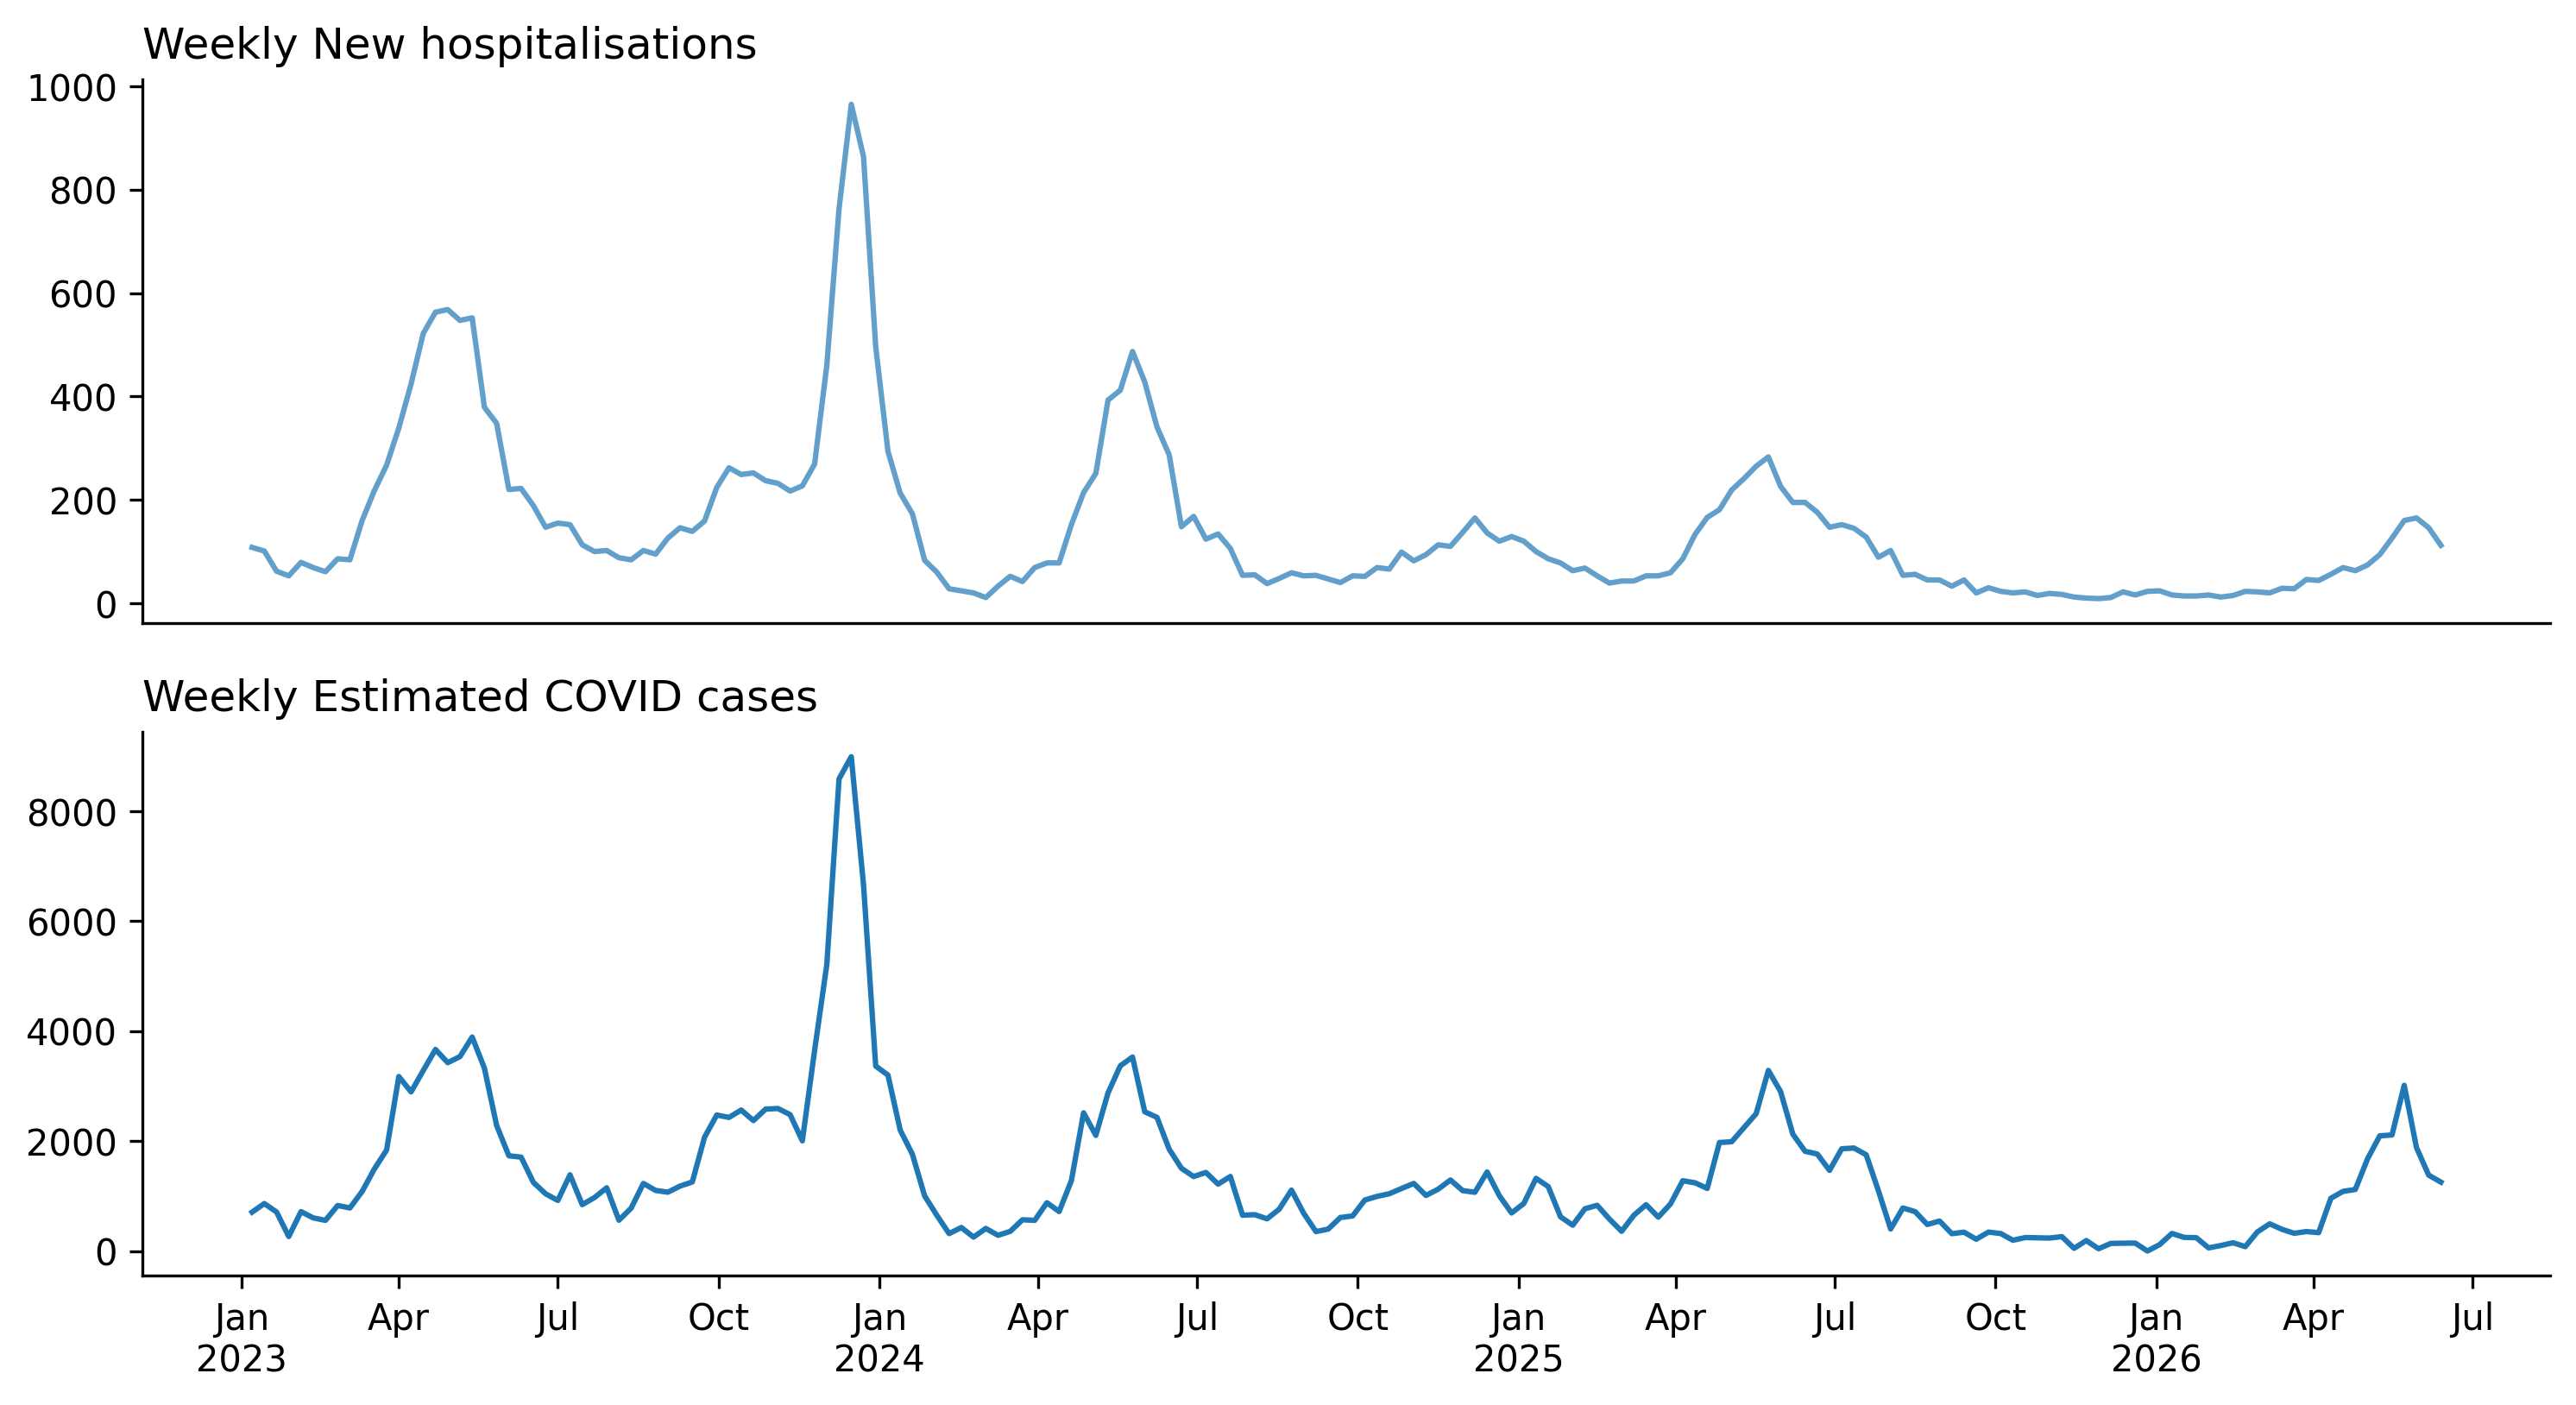

In [ ]:
covid_ari_d = pd.read_excel("../sg_data/agg_ari_ili.xlsx")

try:
    covid_hosp_d = pd.read_excel(
        "../sg_data/agg_covid_hosp_variant.xlsx",
        sheet_name="NEW_ACTIVE_HOSPITALISATION",
    )
except FileNotFoundError:
    covid_hosp_d = None

if covid_hosp_d is not None:
    covid_hosp_d.rename(columns={"YEAR": "year", "EPI-WEEK": "epi_week"}, inplace=True)


def process_weeks_d(df):
    date_temp = df.apply(get_dates, axis=1)
    df = pd.concat([df, date_temp], axis=1)
    df[["start_date", "end_date"]] = df[["start_date", "end_date"]].apply(pd.to_datetime)
    df["year_week"] = df["year"].astype(str) + "-" + df["epi_week"].astype(str)
    return df


def get_dates(row):
    try:
        epi_week = Week(int(row["year"]), int(row["epi_week"]))
        return pd.Series({
            "start_date": epi_week.startdate(),
            "end_date": epi_week.enddate(),
        })
    except Exception:
        return pd.Series({
            "start_date": None,
            "end_date": None,
        })


covid_ari_d = process_weeks_d(covid_ari_d)

if covid_hosp_d is not None:
    covid_hosp_d = process_weeks_d(covid_hosp_d)
    covid_hosp_d.columns = covid_hosp_d.columns.str.lower()

covid_ari_d["ari_covid_positivity"] = (
    covid_ari_d["ari_covid_pos"] / covid_ari_d["ari_samples"]
)
#est covid case count at poly
covid_ari_d['est_covid_cases'] = covid_ari_d['poly_ari_attendances'] * covid_ari_d['ari_covid_positivity']

covid_ari_d["poly_ari_attendances_adjusted"] = (covid_ari_d['poly_ari_attendances'] / covid_ari_d['working_days']) * 5.5

covid_ari_d["est_covid_cases_adj"] = (
    covid_ari_d["poly_ari_attendances_adjusted"] * covid_ari_d["ari_covid_positivity"]
)

if covid_hosp_d is None:
    covid_ari_hosp_d = covid_ari_d.copy()
else:
    covid_ari_hosp_d = covid_ari_d.merge(
        covid_hosp_d[["year_week", "new_hospitalisation_cases"]],
        how="left",
        on=["year_week"],
    )

PRIMARY_TARGET_COL = "est_covid_cases_adj"
PRIMARY_TARGET_LABEL = "Estimated COVID cases"
HOSP_TARGET_COL = "new_hospitalisation_cases"
HOSP_TARGET_LABEL = "New hospitalisations"

fig, ax = plt.subplots(2, 1, figsize=(12, 6), dpi=300)
plt.subplots_adjust(hspace=0.2)

ax[0].plot(covid_ari_hosp_d["end_date"], covid_ari_hosp_d[HOSP_TARGET_COL], alpha=0.7)
ax[1].plot(covid_ari_hosp_d["end_date"], covid_ari_hosp_d[PRIMARY_TARGET_COL])

for axis in ax:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

ax[0].set_title(f"Weekly {HOSP_TARGET_LABEL}", loc="left")
ax[1].set_title(f"Weekly {PRIMARY_TARGET_LABEL}", loc="left")
ax[0].set_xticks([])
format_quarterly_axis(ax[1])

plt.show()


### Specify model components

### 1) Generation time, Infection to hospitalisation and primary care delays

In [8]:
# Delays
# onset_to_hosp = pd.read_csv('../sg_data/dist/dist_onset_hosp.csv') # SG COVID 2020 Data
# onset_to_hosp_dist = onset_to_hosp.onset_hosp / sum(onset_to_hosp.onset_hosp)

onset_hosp_mean = 8
onset_hosp_sd = 2
onset_hosp_shape, onset_hosp_scale = gamma_convert_param(onset_hosp_mean, onset_hosp_sd) 

j = jnp.arange(0,14)
onset_hosp_dist = dist.Gamma(concentration=onset_hosp_shape, rate=1/onset_hosp_scale)
onset_hosp_raw = jnp.exp(onset_hosp_dist.log_prob(j))
onset_to_hosp_dist = onset_hosp_raw / onset_hosp_raw.sum()

## (2) COVID Generation time interval (mean and sd from Vattiatio et al DOI: 10.1016/j.epidem.2022.100657)
gen_time_mean = 3.3
gen_time_sd = 1.3
gen_time_shape, gen_time_scale = gamma_convert_param(gen_time_mean, gen_time_sd) 

x = jnp.arange(0, 101)
gamma_dist = dist.Gamma(concentration=gen_time_shape, rate=1/gen_time_scale)
gen_time_raw = jnp.exp(gamma_dist.log_prob(x))

gen_time_dist = gen_time_raw / gen_time_raw.sum() #normalise
gen_int_rv = DeterministicPMF(name="gen_int", value=gen_time_dist[:15])

## (3) infection to hospitalisation  - Convolute incubation with onset to hospitalisation
# source: Jantien et al (2022) DOI: 10.2807/1560-7917
x = jnp.arange(0, 11)  # 0:1:10
weibull_dist = dist.Weibull(concentration=1.5, scale=3.2)

incubation_raw = jnp.exp(weibull_dist.log_prob(x))
incub_norm = incubation_raw / incubation_raw.sum()

inf_hosp_dist = conv(incub_norm, onset_to_hosp_dist)

inf_hosp_int = DeterministicPMF(
    name="inf_hosp_int", value=inf_hosp_dist
)

## onset to primary care visits, https://www.thelancet.com/journals/lanwpc/article/PIIS2666-6065(23)00237-7/fulltext
x = jnp.arange(0,7)
ons_primary_dist = dist.Gamma(concentration = 1.2, rate = 1/0.9) #mean 1.3, sd = 1.2
ons_primary_raw = jnp.exp(ons_primary_dist.log_prob(x))
ons_primary_norm = ons_primary_raw / sum(ons_primary_raw)

# Infection to primary care visit convolution
inf_primary_dist = DeterministicPMF('inf_primary_dist', conv(incub_norm, ons_primary_norm))

# n_initialization_points = max(gen_int_rv.sample().size, inf_hosp_int_array.size, inf_shed_int_array.size) - 1
n_initialization_points = max(gen_int_rv.sample().size, inf_hosp_dist.size, inf_primary_dist().size) - 1

### Case ascertainment probabilities (symptomatic, health-seek, patient share between private/public primary care)

In [9]:
# Probability of symptomatic given COVID infections:
# https://www.thelancet.com/journals/laninf/article/PIIS1473-3099(20)30833-1/fulltext
# https://www.acpjournals.org/doi/10.7326/M20-3012?
p_sym = DistributionalVariable('p_sym',distribution = dist.Beta(40,60))

hosp_rate = DistributionalVariable(
    name='hosp_rate', distribution=dist.Uniform(0.001,0.2)
)

## Ascertainment rate for primary care visits
class Alpha_primary(RandomVariable):

    @staticmethod
    def validate():
        return None

    def sample(self, p_sym):

        # https://www.thelancet.com/journals/lanwpc/article/PIIS2666-6065%2823%2900237-7/fulltext?
        # ~75% seek primary care, later periods of COVID (2021-2022). Now COVID endemic, lesser testing and healthcare seeking.
        p_hseek_dist = DistributionalVariable('p_hseek', distribution = dist.Beta(60,40))
        p_hseek = p_hseek_dist.sample()

        p_visit_dist = DistributionalVariable('p_visit', distribution = dist.Beta(15,85))
        p_visit = p_visit_dist.sample()

        alpha_primary = numpyro.deterministic('alpha_primary',p_sym*p_hseek*p_visit)
        
        return alpha_primary

alpha_primary_rv = Alpha_primary()

### Latent infection process

In [10]:
i0_first_obs_n_rv = DistributionalVariable(name='I_pre_init',distribution=dist.Gamma(concentration=1.0,rate=1.0/50.0))

# The random walk on log Rt, with an inferred s.d. Here, we
# construct a custom RandomVariable.
class RtRandomWalk(RandomVariable):
    def validate(self):
        pass

    def sample(self, n: int, **kwargs) -> tuple:
        sd_rt = numpyro.sample("Rt_random_walk_sd", dist.HalfNormal(0.025))

        # Random walk step
        step_rv = randomvariable.DistributionalVariable(
            name="rw_step_rv", distribution=dist.Normal(0, sd_rt)
        )

        rt_init_rv = randomvariable.DistributionalVariable(
            name="init_log_rt", distribution=dist.Normal(0, 0.2)
        )

        # Random walk process
        base_rv = process.RandomWalk(
            name="log_rt",
            step_rv=step_rv,
        )

        # Transforming the random walk to the Rt scale
        rt_rv = randomvariable.TransformedVariable(
            name="Rt_rv",
            base_rv=base_rv,
            transforms=transformation.ExpTransform(),
        )
        init_rt = rt_init_rv.sample()

        return rt_rv.sample(n=n, init_vals=init_rt, **kwargs)

rtproc = RtRandomWalk()


inf_feedback_strength_rv = DistributionalVariable(
        "inf_feedback_raw",
        dist.HalfNormal(2e-4),
    )

#For feedback
latent_inf_feedback = LatentInfectionProcess(
    i0_first_obs_n_rv = i0_first_obs_n_rv,
    Rt_process_rv = rtproc,
    feedback = True,
    generation_interval_pmf_rv=gen_int_rv,
    infection_feedback_strength_rv=inf_feedback_strength_rv,
    infection_feedback_pmf_rv=gen_int_rv,
    n_initialization_points=n_initialization_points
)

#For no feedback
latent_inf_no_feedback = LatentInfectionProcess(
    i0_first_obs_n_rv = i0_first_obs_n_rv,
    Rt_process_rv = rtproc,
    feedback = False,
    generation_interval_pmf_rv=gen_int_rv,
    infection_feedback_strength_rv=inf_feedback_strength_rv,
    infection_feedback_pmf_rv=gen_int_rv,
    n_initialization_points=n_initialization_points
)

### Observation process

In [ ]:
#Observation model - primary care cases
nb_conc_primary_rv = TransformedVariable(
    "concentration_primary",
    randomvariable.DistributionalVariable(
        name="concentration_raw_primary",
        distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
    ),
    transformation.PowerTransform(-2),
)

obs_p = observation.NegativeBinomialObservation(
    "negbinom_primary_rv",
    concentration_rv=nb_conc_primary_rv,    
)
poly_obs = PolyVisitObservationProcess(p_poly_mean_rv = alpha_primary_rv,
                                       inf_to_poly_rv=inf_primary_dist,
                                       poly_obs_process_rv=obs_p,
                                       p_sym=p_sym)

#Observation model - hospital cases
nb_conc_hosp_rv = TransformedVariable(
    "concentration_hosp",
    randomvariable.DistributionalVariable(
        name="concentration_raw_hosp",
        distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
    ),
    transformation.PowerTransform(-2),
)

obs_h = observation.NegativeBinomialObservation(
    "negbinom_hosp_rv",
    concentration_rv=nb_conc_hosp_rv,    
)
hosp_obs = HospObservationProcess(p_hosp_mean_rv = hosp_rate,
                                       inf_to_hosp_rv=inf_hosp_int,
                                       hosp_obs_process_rv=obs_h,)

### Forecasts


In [16]:
HORIZON_PREFIXES = {
    1: "one_week",
    2: "two_week",
    3: "three_week",
    4: "four_week",
}

def maybe_smooth_series(dates, values, use_loess):
    values = np.asarray(values, dtype=float)
    if not use_loess:
        return values
    return loess(dates, values).predict(dates).values

def run_model(model, fit_d, use_loess=True, primary_target_col=PRIMARY_TARGET_COL):
    observed_hosp = maybe_smooth_series(
        fit_d["end_date"],
        fit_d[HOSP_TARGET_COL],
        use_loess=use_loess,
    )
    observed_poly = maybe_smooth_series(
        fit_d["end_date"],
        fit_d[primary_target_col],
        use_loess=use_loess,
    )

    model.run(
        num_samples=1000,
        num_warmup=1000,
        rng_key=jax.random.key(54),
        mcmc_args=dict(progress_bar=False, num_chains=2),
        data_observed_poly=observed_poly,
        data_observed_hosp=observed_hosp,
        sample_poly_visits=True,
        sample_hospital_admissions=True,
    )

    return model

def forecast(model, fit_d, weeks_ahead):
    n_forecast_days = weeks_ahead * 7

    ppc_samples = model.posterior_predictive(
        n_datapoints=len(fit_d) * 7 + n_forecast_days
    )

    return az.from_numpyro(
        posterior=model.mcmc,
        posterior_predictive=ppc_samples,
    )

def stack_weekly_draws(idata, site_name, total_weeks):
    return np.asarray(idata.posterior_predictive[site_name]).reshape(-1, total_weeks)

def summarize_future_weekly(
    idata,
    observed_site_name,
    mu_site_name,
    total_weeks,
    weeks_ahead,
):
    observed_draws = stack_weekly_draws(idata, observed_site_name, total_weeks)
    mu_draws = stack_weekly_draws(idata, mu_site_name, total_weeks)

    future_observed = observed_draws[:, -weeks_ahead:]
    future_mu = mu_draws[:, -weeks_ahead:]
    quantiles = np.quantile(
        future_observed,
        q=[0.025, 0.25, 0.5, 0.75, 0.975],
        axis=0,
    )

    return {
        "pred": quantiles[2],
        # "pred_mu": np.median(future_mu, axis=0),
        "lower2.5": quantiles[0],
        "lower25": quantiles[1],
        "upper75": quantiles[3],
        "upper97.5": quantiles[4],
    }


In [20]:
forecast_ahead = 4  # weeks
fit_length = 20  # weeks

rolling_start_window = np.arange(
    0,
    len(covid_ari_hosp_d) - forecast_ahead - fit_length + 1,
)
rolling_end_window = rolling_start_window + fit_length



OUTCOME_SPECS = {
    "hosp": {
        "observed_site_name": "negbinom_hosp_rv",
        "mu_site_name": "mu_hosp_weekly",
        "target_col": HOSP_TARGET_COL,
        "target_label": HOSP_TARGET_LABEL,
    },
}

def build_model(feedback):
    latent_process = latent_inf_feedback if feedback else latent_inf_no_feedback
    return PyrenewModel(
        population_size=1,
        latent_infection_process_rv=latent_process,
        poly_visit_obs_process_rv=poly_obs,
        hosp_admit_obs_process_rv=hosp_obs,
    )

def init_forecast_dict():
    forecast_dict = {
        "model_name": [],
        "outcome": [],
        "target_series": [],
        "target_label": [],
        "use_loess": [],
        "feedback": [],
        "fit_length": [],
        "forecast_ahead": [],
        "year": [],
        "epi_week": [],
        "end_date": [],
        "obs": [],
    }
    for prefix in HORIZON_PREFIXES.values():
        for suffix in [
            "pred",
            "pred_mu",
            "lower2.5",
            "lower25",
            "upper75",
            "upper97.5",
            "date",
            "obs",
        ]:
            forecast_dict[f"{prefix}_{suffix}"] = []
    return forecast_dict

def append_forecast_row(forecast_dict, fit_d, fore_d, summary, config, spec, outcome_name):
    forecast_dict["model_name"].append(config["model_name"])
    forecast_dict["outcome"].append(outcome_name)
    forecast_dict["target_series"].append(spec["target_col"])
    forecast_dict["target_label"].append(spec["target_label"])
    forecast_dict["use_loess"].append(config["use_loess"])
    forecast_dict["feedback"].append(config["feedback"])
    forecast_dict["fit_length"].append(len(fit_d))
    forecast_dict["forecast_ahead"].append(forecast_ahead)

    last_fit = fit_d.iloc[-1]
    forecast_dict["year"].append(last_fit["year"])
    forecast_dict["epi_week"].append(last_fit["epi_week"])
    forecast_dict["end_date"].append(last_fit["end_date"])
    forecast_dict["obs"].append(last_fit[spec["target_col"]])

    for horizon, prefix in HORIZON_PREFIXES.items():
        future_row = fore_d.iloc[len(fit_d) + horizon - 1]
        forecast_dict[f"{prefix}_pred"].append(summary["pred"][horizon - 1])
        forecast_dict[f"{prefix}_pred_mu"].append(summary["pred_mu"][horizon - 1])
        forecast_dict[f"{prefix}_lower2.5"].append(summary["lower2.5"][horizon - 1])
        forecast_dict[f"{prefix}_lower25"].append(summary["lower25"][horizon - 1])
        forecast_dict[f"{prefix}_upper75"].append(summary["upper75"][horizon - 1])
        forecast_dict[f"{prefix}_upper97.5"].append(summary["upper97.5"][horizon - 1])
        forecast_dict[f"{prefix}_date"].append(future_row["end_date"])
        forecast_dict[f"{prefix}_obs"].append(future_row[spec["target_col"]])

def run_rolling_forecasts(config):
    forecast_dicts = {
        outcome_name: init_forecast_dict()
        for outcome_name in OUTCOME_SPECS
    }

    for step, (start, end) in enumerate(zip(rolling_start_window, rolling_end_window)):
        fit_d = covid_ari_hosp_d.iloc[start:end].copy()
        fore_d = covid_ari_hosp_d.iloc[start:(end + forecast_ahead)].copy()

        print(f"fitting {config['model_name']} for step {step}")
        fitted_model = run_model(
            build_model(config["feedback"]),
            fit_d=fit_d,
            use_loess=config["use_loess"],
            primary_target_col=PRIMARY_TARGET_COL,
        )
        idata = forecast(fitted_model, fit_d, weeks_ahead=forecast_ahead)
        total_weeks = len(fore_d)

        for outcome_name, spec in OUTCOME_SPECS.items():
            summary = summarize_future_weekly(
                idata,
                observed_site_name=spec["observed_site_name"],
                mu_site_name=spec["mu_site_name"],
                total_weeks=total_weeks,
                weeks_ahead=forecast_ahead,
            )
            append_forecast_row(
                forecast_dicts[outcome_name],
                fit_d=fit_d,
                fore_d=fore_d,
                summary=summary,
                config=config,
                spec=spec,
                outcome_name=outcome_name,
            )

    return {
        outcome_name: pd.DataFrame(forecast_dict)
        for outcome_name, forecast_dict in forecast_dicts.items()
    }

### Run latest week forecast based on agg_ari_ili.xlsx

In [ ]:
forecast_ahead = 4  # weeks
fit_length = 20  # weeks

d_main = covid_ari_hosp_d.iloc[-20:]

MODEL_CONFIGS = {
    "No Loess + FB": {
        "model_name": "No Loess + FB",
        "file_stub": "noloess_feedback",
        "use_loess": False,
        "feedback": True,
    },
}

OUTCOME_SPECS = {
    "hosp": {
        "observed_site_name": "negbinom_hosp_rv",
        "mu_site_name": "mu_hosp_weekly",
        "target_col": HOSP_TARGET_COL,
        "target_label": HOSP_TARGET_LABEL,
    },
}

fitted_model = run_model(
            build_model(MODEL_CONFIGS['No Loess + FB']["feedback"]),
            fit_d=d_main,
            use_loess=MODEL_CONFIGS['No Loess + FB']["use_loess"],
            primary_target_col=PRIMARY_TARGET_COL,
        )

idata = forecast(fitted_model, d_main, weeks_ahead=forecast_ahead)
total_weeks = len(d_main)

for outcome_name, spec in OUTCOME_SPECS.items():
    summary = summarize_future_weekly(
        idata,
        observed_site_name=spec["observed_site_name"],
        mu_site_name=spec["mu_site_name"],
        total_weeks=total_weeks,
        weeks_ahead=forecast_ahead,
    )
    

In [59]:
summary

{'pred': array([51. , 59. , 63.5, 70. ]),
 'lower2.5': array([ 6.,  8.,  8., 11.]),
 'lower25': array([20., 23., 28., 33.]),
 'upper75': array([113.25, 113.  , 117.  , 125.  ]),
 'upper97.5': array([175.   , 183.   , 173.05 , 177.025])}

### M3 forecast for whole dataset


In [1]:
forecast_ahead = 4  # weeks
fit_length = 20  # weeks

rolling_start_window = np.arange(
    0,
    len(covid_ari_hosp_d) - forecast_ahead - fit_length + 1,
)
rolling_end_window = rolling_start_window + fit_length

MODEL_CONFIGS = {
    # "Loess + FB": {
    #     "model_name": "Loess + FB",
    #     "file_stub": "loess_feedback",
    #     "use_loess": True,
    #     "feedback": True,
    # },
    "No Loess + FB": {
        "model_name": "No Loess + FB",
        "file_stub": "noloess_feedback",
        "use_loess": False,
        "feedback": True,
    },
    # "Loess + No FB": {
    #     "model_name": "Loess + No FB",
    #     "file_stub": "loess_nofeedback",
    #     "use_loess": True,
    #     "feedback": False,
    # },
    # "No Loess + No FB": {
    #     "model_name": "No Loess + No FB",
    #     "file_stub": "noloess_nofeedback",
    #     "use_loess": False,
    #     "feedback": False,
    # },
}

NameError: name 'np' is not defined

In [22]:
M3_TARGET_SERIES = "m3"
M3_TARGET_LABEL = "Estimated health-seeking infections (M3)"
M3_CONFIG = MODEL_CONFIGS["No Loess + FB"]
M3_FORECAST_PATH = f"../forecast_results/covid/m3_{M3_CONFIG['file_stub']}.csv"

def flatten_chain_draw(values, n_cols=None):
    arr = np.asarray(values)
    if n_cols is None:
        return arr.reshape(-1)
    return arr.reshape(-1, n_cols)


class CovidModelM3AlphaPrimary(RandomVariable):
    @staticmethod
    def validate():
        return None

    def sample(self, p_sym, n=None):
        p_hseek = DistributionalVariable(
            "p_hseek",
            distribution=dist.Beta(60, 40),
        ).sample()
        p_visit = DistributionalVariable(
            "p_visit",
            distribution=dist.Beta(15, 85),
        ).sample()
        return numpyro.deterministic("alpha_primary", p_sym * p_hseek * p_visit)


class CovidModelM3RtRandomWalk(RandomVariable):
    def validate(self):
        pass

    def sample(self, n: int, **kwargs) -> tuple:
        sd_rt = numpyro.sample("Rt_random_walk_sd", dist.HalfNormal(0.025))

        step_rv = randomvariable.DistributionalVariable(
            name="rw_step_rv",
            distribution=dist.Normal(0, sd_rt),
        )
        rt_init_rv = randomvariable.DistributionalVariable(
            name="init_log_rt",
            distribution=dist.Normal(0, 0.2),
        )
        base_rv = process.RandomWalk(
            name="log_rt",
            step_rv=step_rv,
        )
        rt_rv = randomvariable.TransformedVariable(
            name="Rt_rv",
            base_rv=base_rv,
            transforms=t.ExpTransform(),
        )

        return rt_rv.sample(n=n, init_vals=rt_init_rv.sample(), **kwargs)


def build_covid_model_m3_latent_infections(feedback=False):
    if not feedback:
        return latent.Infections()

    feedback_strength_rv = DistributionalVariable(
        "inf_feedback_raw",
        dist.HalfNormal(2e-4),
    )
    return latent.InfectionsWithFeedback(
        infection_feedback_strength=feedback_strength_rv,
        infection_feedback_pmf=gen_int_rv,
    )


def build_covid_model_m3(feedback=False):
    p_sym_rv = DistributionalVariable(
        "p_sym",
        distribution=dist.Beta(40, 60),
    )
    hosp_rate_rv = DistributionalVariable(
        name="hosp_rate",
        distribution=dist.Uniform(1e-4, 0.1),
    )
    alpha_primary_rv = CovidModelM3AlphaPrimary()

    latent_severe_primary_rv = latent.SeverePrimary(
        infection_to_severe_interval_rv=inf_hosp_int,
        infection_to_primary_interval_rv=inf_primary_dist,
        infection_severe_ratio_rv=hosp_rate_rv,
        infection_primary_ratio_rv=alpha_primary_rv,
        symptomatic_ratio_rv=p_sym_rv,
    )
    i0_rv = InfectionInitializationProcess(
        "I0_initialization",
        DistributionalVariable(
            name="I0",
            distribution=dist.LogNormal(2.5, 1),
        ),
        InitializeInfectionsZeroPad(n_initialization_points),
    )
    nb_conc_hosp_rv = TransformedVariable(
        "concentration_hosp",
        randomvariable.DistributionalVariable(
            name="concentration_raw_hosp",
            distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
        ),
        t.PowerTransform(-2),
    )
    nb_conc_primary_rv = TransformedVariable(
        "concentration_primary",
        randomvariable.DistributionalVariable(
            name="concentration_raw_primary",
            distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
        ),
        t.PowerTransform(-2),
    )

    return model.SeverePrimaryModel(
        latent_infections_rv=build_covid_model_m3_latent_infections(feedback),
        latent_severe_primary_rv=latent_severe_primary_rv,
        I0_rv=i0_rv,
        gen_int_rv=gen_int_rv,
        Rt_process_rv=CovidModelM3RtRandomWalk(),
        severe_admission_obs_process_rv=observation.NegativeBinomialObservation(
            "negbinom_hosp_rv",
            concentration_rv=nb_conc_hosp_rv,
        ),
        primary_care_cases_obs_process_rv=observation.NegativeBinomialObservation(
            "negbinom_primary_rv",
            concentration_rv=nb_conc_primary_rv,
        ),
    )


def run_covid_model_m3(
    fit_d,
    use_loess=False,
    primary_target_col=PRIMARY_TARGET_COL,
    feedback=False,
):
    observed_hosp = maybe_smooth_series(
        fit_d["end_date"],
        fit_d[HOSP_TARGET_COL],
        use_loess=use_loess,
    )
    observed_primary = maybe_smooth_series(
        fit_d["end_date"],
        fit_d[primary_target_col],
        use_loess=use_loess,
    )

    fit_model = build_covid_model_m3(feedback=feedback)
    fit_model.run(
        num_samples=1000,
        num_warmup=1000,
        rng_key=jax.random.key(54),
        mcmc_args=dict(progress_bar=False, num_chains=2),
        data_observed_severe_admissions=observed_hosp,
        data_observed_primary_care_cases=observed_primary,
        weekly_obs=True,
    )
    return fit_model


def forecast_covid_model_m3(fit_model, total_weeks):
    ppc_samples = fit_model.posterior_predictive(n_datapoints=total_weeks * 7)
    return az.from_numpyro(
        posterior=fit_model.mcmc,
        posterior_predictive=ppc_samples,
    )


def get_covid_model_m3_weekly_draws(
    latent_infections,
    p_sym,
    p_hseek,
    total_weeks,
    n_inf_start=n_initialization_points,
):
    n_days_total = n_inf_start + total_weeks * 7
    latent_draws = flatten_chain_draw(latent_infections, n_cols=n_days_total)
    latent_draws = latent_draws[:, n_inf_start:]
    scale = (flatten_chain_draw(p_sym) * flatten_chain_draw(p_hseek))[:, None]

    if latent_draws.shape[0] != scale.shape[0]:
        raise ValueError(
            "Posterior sample counts do not align for M3 estimation."
        )

    m3_daily = latent_draws * scale
    return m3_daily.reshape(-1, total_weeks, 7).sum(axis=2)


def summarize_future_covid_model_m3(
    idata,
    fit_weeks,
    total_weeks,
    weeks_ahead,
    n_inf_start=n_initialization_points,
):
    fit_weekly_draws = get_covid_model_m3_weekly_draws(
        idata.posterior["all_latent_infections"],
        idata.posterior["p_sym"],
        idata.posterior["p_hseek"],
        total_weeks=fit_weeks,
        n_inf_start=n_inf_start,
    )
    forecast_weekly_draws = get_covid_model_m3_weekly_draws(
        idata.posterior_predictive["all_latent_infections"],
        idata.posterior["p_sym"],
        idata.posterior["p_hseek"],
        total_weeks=total_weeks,
        n_inf_start=n_inf_start,
    )
    future_draws = forecast_weekly_draws[:, -weeks_ahead:]
    future_mean = np.mean(future_draws, axis=0)
    quantiles = np.quantile(
        future_draws,
        q=[0.025, 0.25, 0.5, 0.75, 0.975],
        axis=0,
    )

    return {
        "pred": quantiles[2],
        "pred_mu": future_mean,
        "lower2.5": quantiles[0],
        "lower25": quantiles[1],
        "upper75": quantiles[3],
        "upper97.5": quantiles[4],
        "origin_obs": np.median(fit_weekly_draws[:, fit_weeks - 1]),
    }


def append_m3_forecast_row(forecast_dict, fit_d, fore_d, summary, config):
    last_fit = fit_d.iloc[-1]
    forecast_dict["model_name"].append(config["model_name"])
    forecast_dict["outcome"].append(M3_TARGET_SERIES)
    forecast_dict["target_series"].append(M3_TARGET_SERIES)
    forecast_dict["target_label"].append(M3_TARGET_LABEL)
    forecast_dict["use_loess"].append(config["use_loess"])
    forecast_dict["feedback"].append(config["feedback"])
    forecast_dict["fit_length"].append(len(fit_d))
    forecast_dict["forecast_ahead"].append(forecast_ahead)
    forecast_dict["year"].append(last_fit["year"])
    forecast_dict["epi_week"].append(last_fit["epi_week"])
    forecast_dict["end_date"].append(last_fit["end_date"])
    forecast_dict["obs"].append(summary["origin_obs"])

    for horizon, prefix in HORIZON_PREFIXES.items():
        future_row = fore_d.iloc[len(fit_d) + horizon - 1]
        forecast_dict[f"{prefix}_pred"].append(summary["pred"][horizon - 1])
        forecast_dict[f"{prefix}_pred_mu"].append(summary["pred_mu"][horizon - 1])
        forecast_dict[f"{prefix}_lower2.5"].append(summary["lower2.5"][horizon - 1])
        forecast_dict[f"{prefix}_lower25"].append(summary["lower25"][horizon - 1])
        forecast_dict[f"{prefix}_upper75"].append(summary["upper75"][horizon - 1])
        forecast_dict[f"{prefix}_upper97.5"].append(summary["upper97.5"][horizon - 1])
        forecast_dict[f"{prefix}_date"].append(future_row["end_date"])
        forecast_dict[f"{prefix}_obs"].append(np.nan)


def run_m3_covid_model_forecasts(config=M3_CONFIG):
    forecast_dict = init_forecast_dict()

    for step, (start, end) in enumerate(zip(rolling_start_window, rolling_end_window)):
        fit_d = covid_ari_hosp_d.iloc[start:end].copy()
        fore_d = covid_ari_hosp_d.iloc[start:(end + forecast_ahead)].copy()

        print(f"fitting M3 {config['model_name']} with covid_model spec for step {step}")
        fitted_model = run_covid_model_m3(
            fit_d=fit_d,
            use_loess=config["use_loess"],
            primary_target_col=PRIMARY_TARGET_COL,
            feedback=config["feedback"],
        )
        idata = forecast_covid_model_m3(fitted_model, total_weeks=len(fore_d))
        summary = summarize_future_covid_model_m3(
            idata,
            fit_weeks=len(fit_d),
            total_weeks=len(fore_d),
            weeks_ahead=forecast_ahead,
        )
        append_m3_forecast_row(
            forecast_dict,
            fit_d=fit_d,
            fore_d=fore_d,
            summary=summary,
            config=config,
        )

    return pd.DataFrame(forecast_dict)


fore_m3_df_covid_model = run_m3_covid_model_forecasts()
fore_m3_df_covid_model.to_csv(M3_FORECAST_PATH, index=False)
fore_m3_df_covid_model.head()


fitting M3 No Loess + FB with covid_model spec for step 0


KeyboardInterrupt: 

### M3 for the latest week

In [38]:
forecast_ahead = 4  # weeks
fit_length = 20  # weeks

d_main = covid_ari_hosp_d.iloc[-20:]


fitted_model = run_covid_model_m3(
    fit_d=d_main,
    use_loess=MODEL_CONFIGS['No Loess + FB']["use_loess"],
    primary_target_col=PRIMARY_TARGET_COL,
    feedback=MODEL_CONFIGS['No Loess + FB']["feedback"],
)
idata = forecast_covid_model_m3(fitted_model, total_weeks=len(d_main) + forecast_ahead)
summary = summarize_future_covid_model_m3(
    idata,
    fit_weeks=len(d_main),
    total_weeks=len(d_main) + forecast_ahead,
    weeks_ahead=forecast_ahead,
)

In [39]:
summary

{'pred': array([7625.00463867, 7511.25927734, 7464.15869141, 7427.59277344]),
 'pred_mu': array([8038.561 , 8044.931 , 8105.847 , 8190.1484], dtype=float32),
 'lower2.5': array([2768.69772949, 2022.08569336, 1442.67176819, 1000.42512512]),
 'lower25': array([5814.89904785, 5488.3215332 , 5230.8807373 , 5013.70959473]),
 'upper75': array([ 9696.46240234,  9891.41088867, 10088.3190918 , 10267.9074707 ]),
 'upper97.5': array([15648.88933105, 16984.53583984, 18300.48071289, 20164.95361328]),
 'origin_obs': np.float32(7701.073)}